# OrbitalRoute AI — Redes de Computadoras
## Diseño, simulación y evaluación de una red satelital

**Área:** Redes de Computadoras  
**Proyecto integrador:** OrbitalRoute AI  
**Enfoque:** arquitectura de red, modelos OSI y TCP/IP, direccionamiento IPv4, protocolos, topologías, calidad de servicio (QoS) y selección de rutas.

### Objetivo
Modelar una red híbrida de estaciones terrestres, satélites y nodos de servicio; analizar su conectividad y comparar rutas mediante métricas de latencia, pérdida de paquetes, ancho de banda y disponibilidad.

> **Alcance académico:** los datos y enlaces de este notebook son simulados. No representan telemetría real ni una red satelital desplegada. Los valores sirven para practicar conceptos y comparar métodos.

## 1. Preparación del entorno

Se utilizarán Python, pandas, NumPy, Matplotlib y NetworkX. Si hace falta instalar las bibliotecas, ejecuta en una terminal:
```bash
python -m pip install pandas numpy matplotlib networkx jupyter
```

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

SEED = 42
rng = np.random.default_rng(SEED)
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("NetworkX:", nx.__version__)

Python: 3.14.8
pandas: 3.0.6
NumPy: 2.5.3
NetworkX: 3.7


## 2. Conceptos fundamentales de redes

Una **red de computadoras** conecta dispositivos para intercambiar información mediante medios físicos o inalámbricos y un conjunto de reglas llamado protocolos.

- **Nodo:** dispositivo que origina, recibe o reenvía información.
- **Enlace:** conexión entre dos nodos.
- **Ancho de banda:** capacidad máxima de transmisión, normalmente expresada en Mbps o Gbps.
- **Latencia:** tiempo que tarda un paquete en llegar a su destino, medido aquí en milisegundos.
- **Pérdida de paquetes:** porcentaje de paquetes que no llegan correctamente.
- **Disponibilidad:** proporción de tiempo en que un enlace o servicio está operativo.

En OrbitalRoute AI, las estaciones terrestres se comunican con satélites y estos pueden enlazarse entre sí para transportar tráfico hacia otros puntos.

## 3. Modelos OSI y TCP/IP

El modelo OSI organiza la comunicación en siete capas. TCP/IP agrupa funciones en cuatro capas prácticas.

| OSI | Función | Ejemplos |
|---|---|---|
| 7. Aplicación | Servicios para el usuario | HTTP, DNS |
| 6. Presentación | Formato y codificación | TLS, formatos de datos |
| 5. Sesión | Administración de sesiones | Control de diálogo |
| 4. Transporte | Comunicación extremo a extremo | TCP, UDP |
| 3. Red | Direccionamiento y encaminamiento | IPv4, IPv6, IP |
| 2. Enlace de datos | Tramas y acceso al medio | Ethernet, Wi-Fi |
| 1. Física | Transmisión de señales | Fibra, radio |

**Correspondencia simplificada:** Aplicación OSI (7–5) → Aplicación TCP/IP; Transporte (4) → Transporte; Red (3) → Internet; Enlace y Física (2–1) → Acceso a red.

## 4. Topologías de red

Las topologías describen cómo se conectan los nodos. Una topología en estrella concentra conexiones en un nodo central; una malla ofrece rutas alternativas; una estructura híbrida combina varias formas.

El siguiente ejemplo crea y dibuja tres topologías pequeñas para compararlas.

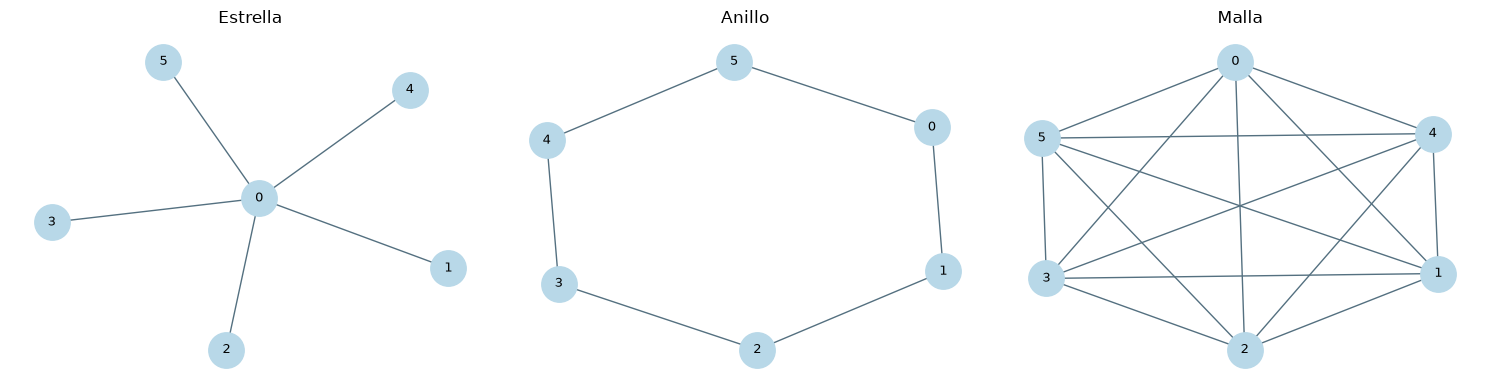

In [2]:
topologies = {
    "Estrella": nx.star_graph(5),
    "Anillo": nx.cycle_graph(6),
    "Malla": nx.complete_graph(6)
}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, graph) in zip(axes, topologies.items()):
    pos = nx.spring_layout(graph, seed=SEED)
    nx.draw_networkx(graph, pos, ax=ax, node_color="#b8d8e8",
                     edge_color="#547080", node_size=650, font_size=9)
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Direccionamiento IPv4 y subnetting

Una dirección IPv4 tiene 32 bits y suele escribirse en cuatro octetos. La máscara de subred separa la parte de red de la parte de host.

Ejemplo didáctico: `192.168.10.0/24` contiene 256 direcciones totales; en una subred IPv4 tradicional quedan 254 direcciones utilizables para hosts (se excluyen dirección de red y broadcast).

La tabla muestra subredes privadas ilustrativas para separar segmentos de la arquitectura.

In [3]:
subnets = pd.DataFrame([
    ["Estaciones terrestres", "192.168.10.0/24", "192.168.10.1", "Administración y acceso"],
    ["Centro de control", "192.168.20.0/24", "192.168.20.1", "Monitoreo y operación"],
    ["Servicios", "192.168.30.0/24", "192.168.30.1", "Aplicaciones y almacenamiento"],
    ["Laboratorio", "192.168.40.0/24", "192.168.40.1", "Pruebas y simulación"],
], columns=["Segmento", "Red IPv4", "Gateway de ejemplo", "Uso"])
subnets

,Segmento,Red IPv4,Gateway de ejemplo,Uso
0,Estaciones terrestres,192.168.10.0/24,192.168.10.1,Administración y acceso
1,Centro de control,192.168.20.0/24,192.168.20.1,Monitoreo y operación
2,Servicios,192.168.30.0/24,192.168.30.1,Aplicaciones y almacenamiento
3,Laboratorio,192.168.40.0/24,192.168.40.1,Pruebas y simulación


## 6. Protocolos y servicios

| Protocolo | Capa TCP/IP | Función |
|---|---|---|
| IP | Internet | Direccionamiento y entrega entre redes |
| TCP | Transporte | Entrega fiable y ordenada |
| UDP | Transporte | Transporte ligero sin garantía de entrega |
| DNS | Aplicación | Traduce nombres a direcciones IP |
| DHCP | Aplicación | Asigna configuración IP automáticamente |
| HTTP/HTTPS | Aplicación | Intercambio de recursos web |
| ICMP | Internet | Mensajes de control y diagnóstico |

La elección del protocolo depende de los requisitos. Por ejemplo, una transferencia que necesita fiabilidad suele utilizar TCP; una aplicación sensible al retardo puede utilizar UDP junto con mecanismos propios de control.

## 7. Construcción de una red simulada

Se definen dos estaciones terrestres, un centro de control, un servidor y ocho satélites. Cada enlace recibe métricas sintéticas: latencia, pérdida, ancho de banda y disponibilidad. El grafo permite estudiar conectividad y rutas alternativas.

In [4]:
nodes = [
    ("GS-MEX", "Estación terrestre"), ("GS-USA", "Estación terrestre"),
    ("CTRL", "Centro de control"), ("SRV", "Servidor"),
] + [(f"SAT-{i:02d}", "Satélite") for i in range(1, 9)]

node_df = pd.DataFrame(nodes, columns=["nodo", "tipo"])
links = [
    ("GS-MEX","SAT-01"),("GS-MEX","SAT-02"),("GS-MEX","SAT-03"),
    ("SAT-01","SAT-02"),("SAT-02","SAT-03"),("SAT-03","SAT-04"),
    ("SAT-04","SAT-05"),("SAT-05","SAT-06"),("SAT-06","SAT-07"),
    ("SAT-07","SAT-08"),("SAT-08","SAT-01"),("SAT-02","SAT-05"),
    ("SAT-03","SAT-06"),("SAT-04","SAT-07"),("SAT-05","SAT-08"),
    ("SAT-06","GS-USA"),("SAT-07","GS-USA"),
    ("GS-MEX","CTRL"),("GS-USA","CTRL"),("CTRL","SRV")
]
link_rows = []
for a, b in links:
    link_rows.append({
        "origen": a, "destino": b,
        "latencia_ms": round(float(rng.uniform(18, 145)), 2),
        "perdida_pct": round(float(rng.uniform(0.05, 2.8)), 2),
        "ancho_banda_mbps": round(float(rng.uniform(40, 900)), 1),
        "disponibilidad_pct": round(float(rng.uniform(96.5, 99.99)), 2)
    })
link_df = pd.DataFrame(link_rows)
display(node_df.head())
display(link_df.head())
print("Nodos:", len(node_df), "| Enlaces:", len(link_df))

,nodo,tipo
0,GS-MEX,Estación terrestre
1,GS-USA,Estación terrestre
2,CTRL,Centro de control
3,SRV,Servidor
4,SAT-01,Satélite


,origen,destino,latencia_ms,perdida_pct,ancho_banda_mbps,disponibilidad_pct
0,GS-MEX,SAT-01,116.29,1.26,778.4,98.93
1,GS-MEX,SAT-02,29.96,2.73,694.6,99.24
2,GS-MEX,SAT-03,34.27,1.29,358.9,99.73
3,SAT-01,SAT-02,99.77,2.31,421.3,97.29
4,SAT-02,SAT-03,88.43,0.23,751.8,98.70


Nodos: 12 | Enlaces: 20


## 8. Exploración de métricas de red

Se resumen las métricas y se visualizan sus distribuciones. Las gráficas ayudan a identificar enlaces con latencia elevada, pérdida considerable o menor capacidad.

,latencia_ms,perdida_pct,ancho_banda_mbps,disponibilidad_pct
count,20.00,20.00,20.00,20.00
mean,81.63,1.45,479.75,98.26
std,35.67,0.68,223.38,1.10
min,21.91,0.23,90.10,96.53
25%,50.86,1.06,327.95,97.43
50%,93.52,1.36,481.40,98.32
75%,114.78,1.89,654.92,99.22
max,126.38,2.73,874.80,99.88


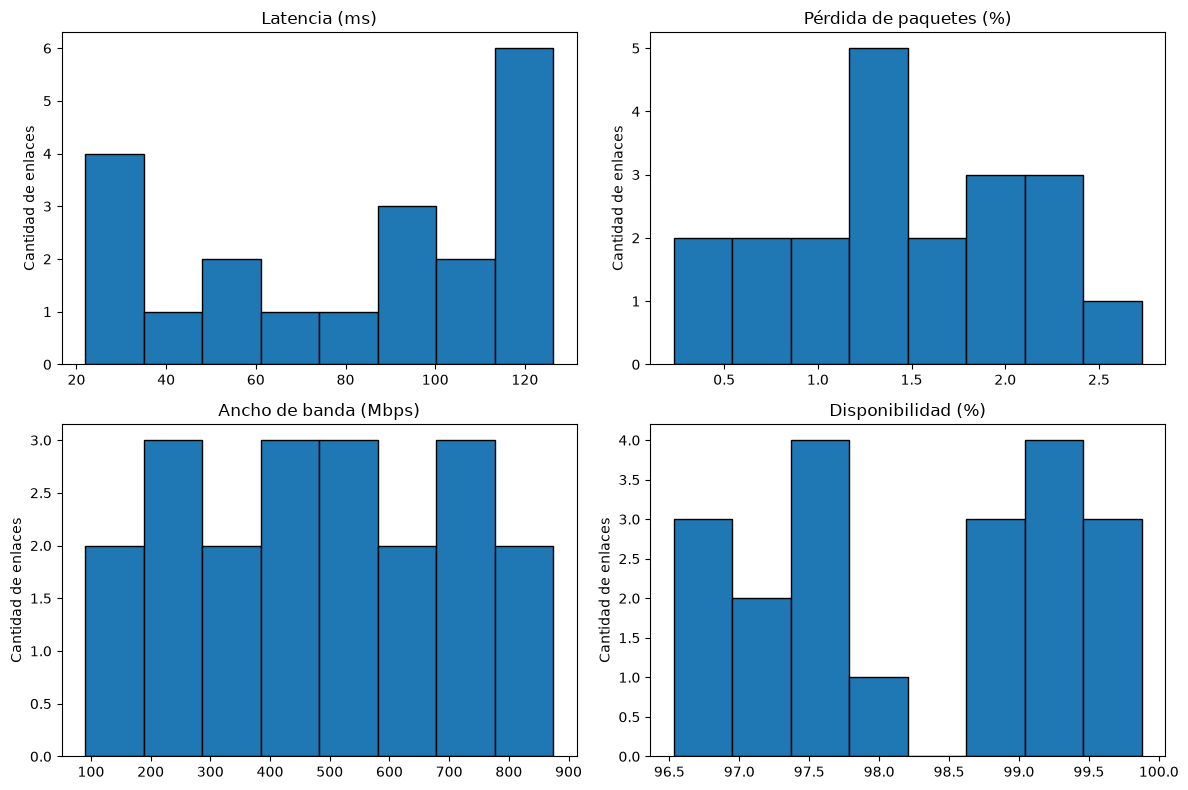

In [5]:
display(link_df[["latencia_ms","perdida_pct","ancho_banda_mbps","disponibilidad_pct"]].describe().round(2))
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
cols = [("latencia_ms","Latencia (ms)"),("perdida_pct","Pérdida de paquetes (%)"),
        ("ancho_banda_mbps","Ancho de banda (Mbps)"),("disponibilidad_pct","Disponibilidad (%)")]
for ax, (col, title) in zip(axes.flat, cols):
    ax.hist(link_df[col], bins=8, edgecolor="black")
    ax.set_title(title)
    ax.set_ylabel("Cantidad de enlaces")
plt.tight_layout()
plt.show()

## 9. Grafo de la red y conectividad

Se construye un grafo no dirigido ponderado. El grosor/etiqueta no representa escala física; el grafo es una abstracción para estudiar conectividad.

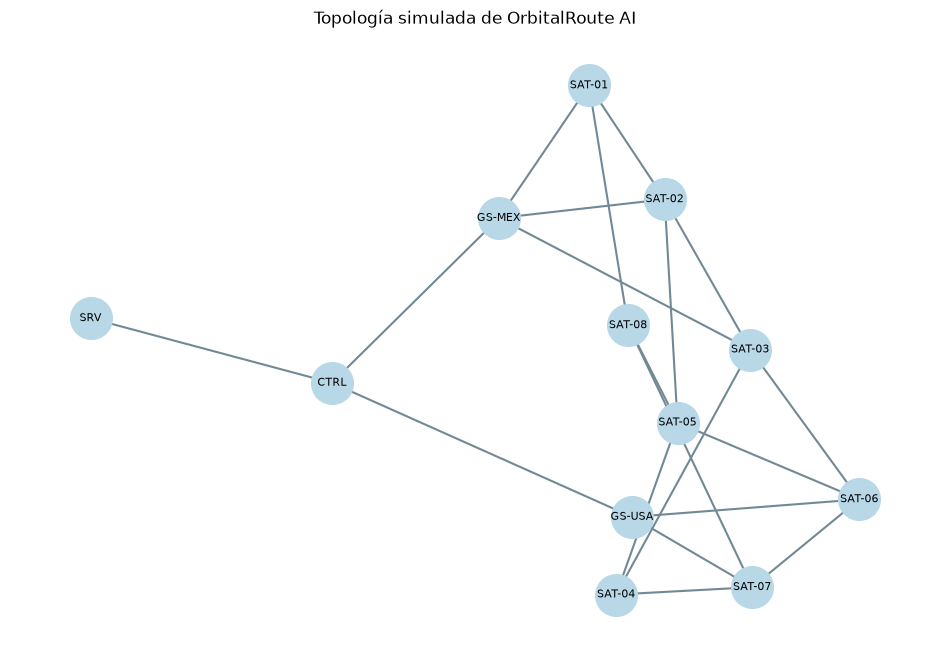

¿Red conexa?: True
Número de componentes: 1
Grado promedio: 3.33


In [6]:
G = nx.Graph()
for _, row in node_df.iterrows():
    G.add_node(row["nodo"], tipo=row["tipo"])
for _, row in link_df.iterrows():
    G.add_edge(row["origen"], row["destino"], **row.to_dict())

pos = nx.spring_layout(G, seed=SEED, k=0.9)
plt.figure(figsize=(12, 8))
nx.draw_networkx(G, pos, node_color="#b8d8e8", edge_color="#718995",
                 node_size=900, font_size=8, width=1.5)
plt.title("Topología simulada de OrbitalRoute AI")
plt.axis("off")
plt.show()

print("¿Red conexa?:", nx.is_connected(G))
print("Número de componentes:", nx.number_connected_components(G))
print("Grado promedio:", round(np.mean([d for _, d in G.degree()]), 2))

## 10. Calidad de servicio (QoS) y costo de enlace

Para comparar rutas se define un costo compuesto ilustrativo:

\[
C(e)=L(e)+4P(e)+0.03\max(0,200-B(e))+2(100-A(e))
\]

donde:
- \(L\): latencia en ms;
- \(P\): pérdida en porcentaje;
- \(B\): ancho de banda en Mbps;
- \(A\): disponibilidad en porcentaje.

Los coeficientes son pesos didácticos, no estándares de la industria. Un costo menor representa una preferencia según esta combinación.

In [7]:
def link_cost(row):
    return (row["latencia_ms"] + 4*row["perdida_pct"]
            + 0.03*max(0, 200-row["ancho_banda_mbps"])
            + 2*(100-row["disponibilidad_pct"]))

for _, row in link_df.iterrows():
    G[row["origen"]][row["destino"]]["costo_qos"] = link_cost(row)

link_df["costo_qos"] = link_df.apply(link_cost, axis=1)
display(link_df.sort_values("costo_qos").head(10).round(2))

,origen,destino,latencia_ms,perdida_pct,ancho_banda_mbps,disponibilidad_pct,costo_qos
17,GS-MEX,CTRL,21.91,1.25,224.5,97.93,31.05
2,GS-MEX,SAT-03,34.27,1.29,358.9,99.73,39.97
9,SAT-07,SAT-08,34.50,1.36,235.1,98.84,42.26
1,GS-MEX,SAT-02,29.96,2.73,694.6,99.24,42.40
7,SAT-05,SAT-06,37.59,1.93,680.5,99.88,45.55
19,CTRL,SRV,55.29,1.87,519.0,99.24,64.29
8,SAT-06,SAT-07,59.38,1.07,443.8,97.16,69.34
10,SAT-08,SAT-01,73.52,2.34,642.2,97.59,87.70
14,SAT-05,SAT-08,76.28,1.61,160.2,96.90,90.11
4,SAT-02,SAT-03,88.43,0.23,751.8,98.70,91.95


## 11. Selección de rutas

Se comparan dos criterios entre la estación terrestre de México y el servidor:
1. Ruta con menor suma de latencias.
2. Ruta con menor costo QoS compuesto.

Dijkstra encuentra la ruta de costo mínimo cuando los pesos son no negativos.

In [8]:
source, target = "GS-MEX", "SRV"
path_latency = nx.shortest_path(G, source, target, weight="latencia_ms")
path_qos = nx.shortest_path(G, source, target, weight="costo_qos")

def path_summary(graph, path, weight):
    total = sum(graph[u][v][weight] for u, v in zip(path[:-1], path[1:]))
    return path, round(total, 2)

print("Ruta de menor latencia:", path_summary(G, path_latency, "latencia_ms"))
print("Ruta de menor costo QoS:", path_summary(G, path_qos, "costo_qos"))

Ruta de menor latencia: (['GS-MEX', 'CTRL', 'SRV'], 77.2)
Ruta de menor costo QoS: (['GS-MEX', 'CTRL', 'SRV'], 95.34)


## 12. Comparación visual de las rutas

Se resaltan las rutas calculadas sobre la misma topología. Esto permite observar que el camino con menor latencia total no necesariamente coincide con el camino que optimiza el costo QoS compuesto.

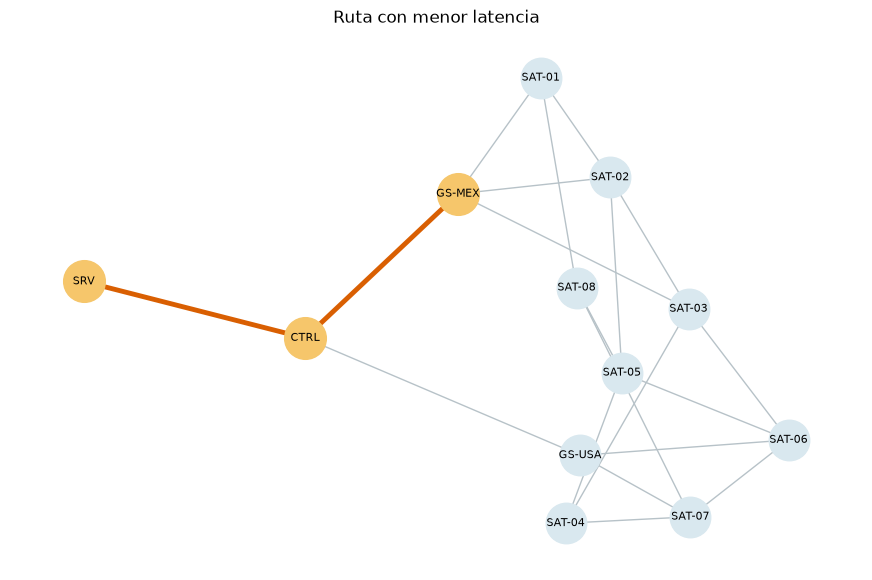

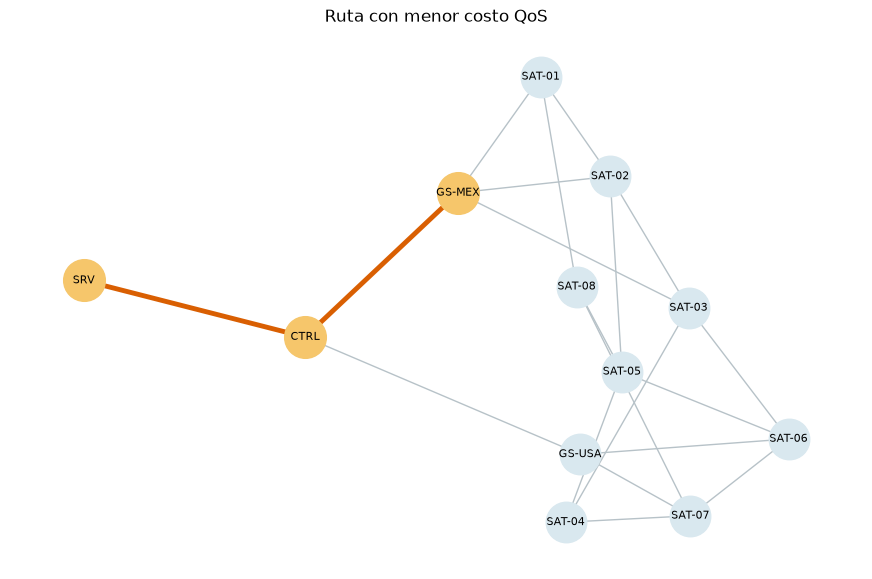

In [9]:
def draw_route(path, title):
    route_edges = list(zip(path[:-1], path[1:]))
    plt.figure(figsize=(11, 7))
    nx.draw_networkx(G, pos, node_color="#d9e8ef", edge_color="#b7c2c8",
                     node_size=850, font_size=8)
    nx.draw_networkx_edges(G, pos, edgelist=route_edges, edge_color="#d95f02", width=3.5)
    nx.draw_networkx_nodes(G, pos, nodelist=path, node_color="#f6c66b", node_size=900)
    plt.title(title)
    plt.axis("off")
    plt.show()

draw_route(path_latency, "Ruta con menor latencia")
draw_route(path_qos, "Ruta con menor costo QoS")

## 13. Simulación sencilla de tráfico

Se generan solicitudes con tamaños y prioridades diferentes. Se estima el tiempo de transmisión de cada solicitud sobre un enlace elegido, usando:

\[
T_{transmisión}(ms)=\frac{Tamaño(MB)\times 8}{Ancho\ de\ banda(Mbps)}\times 1000
\]

La estimación no incluye todos los efectos de una red real (colas, retransmisiones, congestión dinámica ni variaciones del canal).

In [10]:
traffic = pd.DataFrame({
    "flujo": [f"FLUJO-{i:02d}" for i in range(1, 31)],
    "tamano_MB": rng.uniform(0.2, 18, 30).round(2),
    "prioridad": rng.choice(["Alta","Media","Baja"], 30, p=[0.3,0.45,0.25])
})
sample_link = link_df.iloc[0]
traffic["enlace_referencia"] = f'{sample_link["origen"]} → {sample_link["destino"]}'
traffic["tiempo_transmision_ms"] = (
    traffic["tamano_MB"]*8/sample_link["ancho_banda_mbps"]*1000
).round(2)
display(traffic.head(10))

,flujo,tamano_MB,prioridad,enlace_referencia,tiempo_transmision_ms
0,FLUJO-01,12.02,Media,GS-MEX → SAT-01,123.54
1,FLUJO-02,7.43,Alta,GS-MEX → SAT-01,76.36
2,FLUJO-03,14.69,Media,GS-MEX → SAT-01,150.98
3,FLUJO-04,3.17,Media,GS-MEX → SAT-01,32.58
4,FLUJO-05,0.60,Alta,GS-MEX → SAT-01,6.17
5,FLUJO-06,1.80,Baja,GS-MEX → SAT-01,18.50
6,FLUJO-07,13.06,Baja,GS-MEX → SAT-01,134.22
7,FLUJO-08,8.42,Media,GS-MEX → SAT-01,86.54
8,FLUJO-09,3.07,Media,GS-MEX → SAT-01,31.55
9,FLUJO-10,9.12,Media,GS-MEX → SAT-01,93.73


## 14. Rendimiento según tamaño de paquete

La gráfica muestra cómo aumenta el tiempo estimado de transmisión al crecer el tamaño de los datos, manteniendo constante el ancho de banda del enlace de referencia.

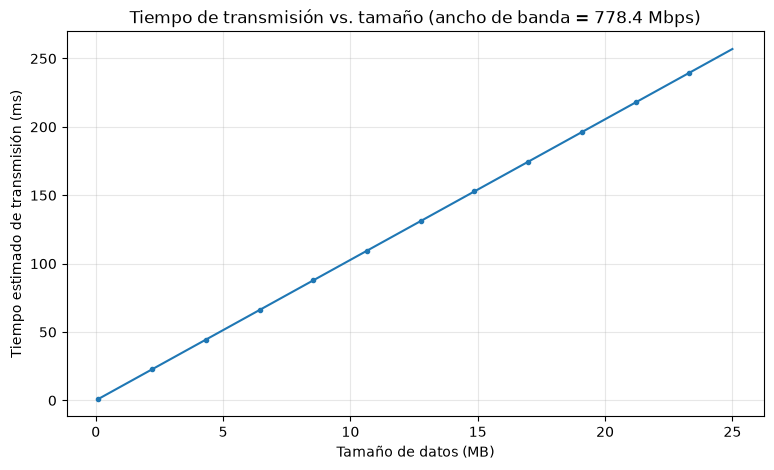

In [11]:
sizes = np.linspace(0.1, 25, 60)
bandwidth = float(sample_link["ancho_banda_mbps"])
tx_ms = sizes*8/bandwidth*1000
plt.figure(figsize=(9, 5))
plt.plot(sizes, tx_ms, marker=".", markevery=5)
plt.xlabel("Tamaño de datos (MB)")
plt.ylabel("Tiempo estimado de transmisión (ms)")
plt.title(f"Tiempo de transmisión vs. tamaño (ancho de banda = {bandwidth:.1f} Mbps)")
plt.grid(True, alpha=0.3)
plt.show()

## 15. Seguridad y buenas prácticas

En una red real, la disponibilidad y el rendimiento deben acompañarse de controles de seguridad:
- Autenticación y autorización de dispositivos y usuarios.
- Cifrado de datos en tránsito.
- Segmentación de redes y mínimo privilegio.
- Actualización y configuración segura de equipos.
- Monitoreo de eventos, registros y alertas.
- Copias de seguridad y procedimientos de continuidad.

Este notebook se limita a una simulación académica y no ejecuta escaneos ni pruebas contra redes reales.

## 16. Conclusiones

La simulación permitió representar una red híbrida mediante nodos y enlaces, revisar topologías, organizar direcciones IPv4 por segmentos y relacionar protocolos con las capas de comunicación. Las métricas de QoS mostraron que una ruta debe evaluarse con más de un criterio: la latencia, la pérdida, el ancho de banda y la disponibilidad pueden favorecer caminos distintos.

El uso de un grafo permitió calcular rutas de menor latencia y de menor costo QoS. La simulación de tráfico ilustró la relación entre tamaño de datos, capacidad del enlace y tiempo de transmisión.

**Limitaciones:** los datos son sintéticos, la topología es simplificada y los pesos del costo QoS son supuestos didácticos. Para un estudio real se requerirían mediciones de red, modelos de movilidad orbital, congestión, colas, interferencia y validación experimental.

## 17. Referencias de consulta

- Kurose, J. F., & Ross, K. W. (2021). *Computer Networking: A Top-Down Approach* (8th ed.). Pearson.
- Tanenbaum, A. S., & Wetherall, D. J. (2011). *Computer Networks* (5th ed.). Pearson.
- Internet Engineering Task Force. (1981). *Internet Protocol (RFC 791)*. https://www.rfc-editor.org/rfc/rfc791
- Internet Engineering Task Force. (1981). *Transmission Control Protocol (RFC 793)*. https://www.rfc-editor.org/rfc/rfc793
- Internet Engineering Task Force. (1980). *User Datagram Protocol (RFC 768)*. https://www.rfc-editor.org/rfc/rfc768
- Odom, W. (2020). *CCNA 200-301 Official Cert Guide, Volume 1*. Cisco Press.

**Nota:** verifica el formato bibliográfico solicitado por tu docente antes de entregar.